# LSTM Stock Price Forecasting, Tested Against a Naive Baseline

**Author:** Steven Ghabyous | Master of Financial Mathematics, NC State University

This project trains a two-layer LSTM to predict Tesla's next-day closing price from the previous 60 days, then asks the question that matters: **does it beat simply predicting that tomorrow's price equals today's?**

## Why the baseline matters

Stock prices are highly persistent, so almost any model that predicts *price levels* will show a high R² and a chart where predictions hug the actual line. That can look impressive while adding nothing. The fair test is a comparison with the **naive (persistence) forecast**, plus **directional accuracy**: how often the model gets the sign of the next day's move right.

> **Revision note.** An earlier version of this notebook reported an R² of 0.97 without a baseline, and it fit the price scaler on the full dataset, including the test period, which leaks information about future price ranges into training. This version fits the scaler on training data only and evaluates the model against the naive forecast.

Run on Google Colab or any environment with TensorFlow and `yfinance` installed.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

---
# 1. Data

Five years of daily split-adjusted closing prices for TSLA (March 9, 2020 to March 7, 2025). The notebook reads a CSV exported from nasdaq.com's historical data page if one is saved at `data/TSLA_nasdaq.csv`, and otherwise downloads the same range from Yahoo Finance with `yfinance`. Tesla pays no dividends, so split-adjusted closes match Yahoo's adjusted closes.

(1257, 1) 2020-03-09 to 2025-03-07


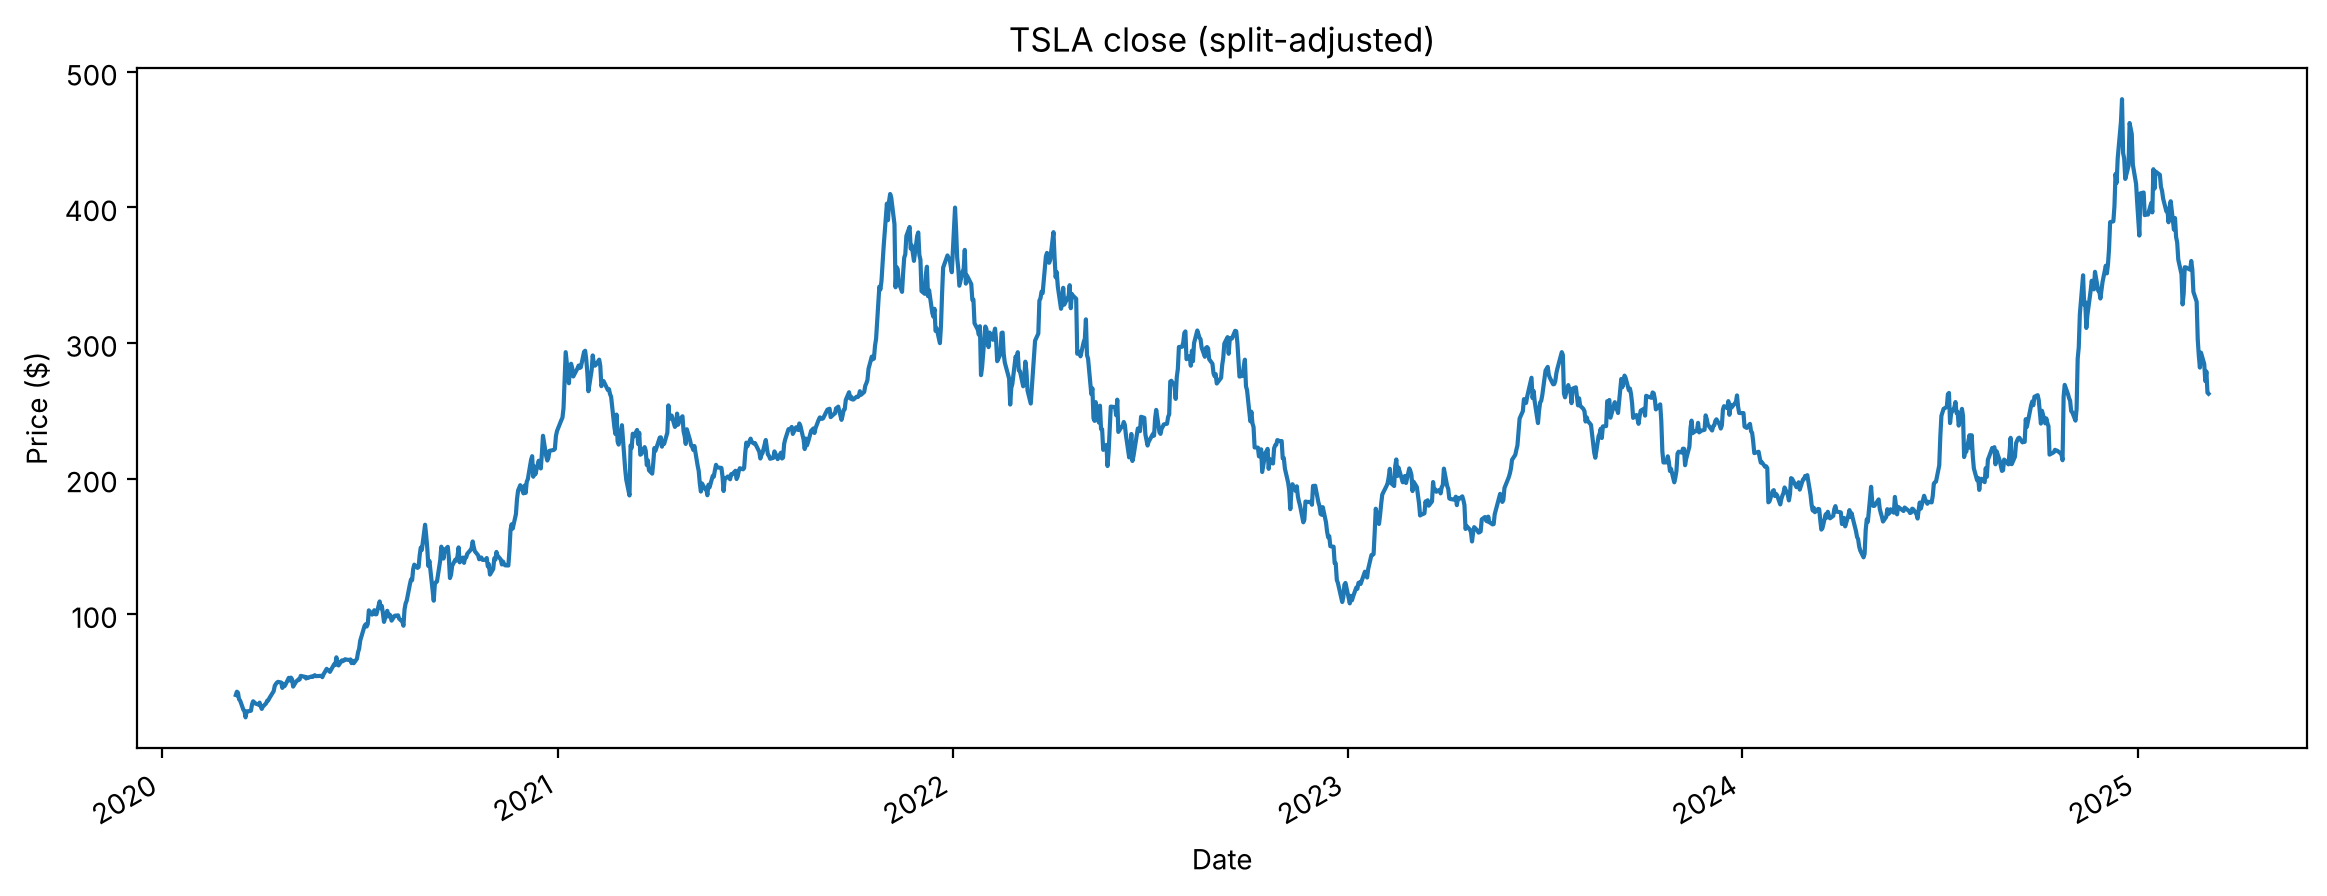

In [2]:
TICKER = 'TSLA'
START, END = '2020-03-09', '2025-03-07'
CSV_PATH = 'data/TSLA_nasdaq.csv'   # daily history exported from nasdaq.com (split-adjusted)

if os.path.exists(CSV_PATH):
    raw = pd.read_csv(CSV_PATH, parse_dates=['Date'])
    raw['Close'] = raw['Close/Last'].astype(str).str.replace('$', '', regex=False).astype(float)
    prices = raw.set_index('Date').sort_index()[['Close']]
else:
    df = yf.download(TICKER, start=START, end='2025-03-08', auto_adjust=False, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    prices = df[['Adj Close']].rename(columns={'Adj Close': 'Close'})

prices = prices.loc[START:END]
print(prices.shape, prices.index.min().date(), 'to', prices.index.max().date())

prices['Close'].plot(figsize=(14, 5), title=f'{TICKER} close (split-adjusted)')
plt.ylabel('Price ($)'); plt.show()

---
# 2. Train/test split and scaling

The first 80% of days are used for training and the last 20% for testing, in time order. The `MinMaxScaler` is **fit on the training prices only**, then applied to the test prices. Fitting it on all prices would tell the model in advance how high and low the test period goes.

Each input is a window of the previous 60 scaled closing prices, and the target is the next day's price.

In [3]:
WINDOW = 60
values = prices['Close'].values.reshape(-1, 1)
train_len = int(len(values) * 0.8)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:train_len])
scaled = scaler.transform(values)

def make_windows(series, start, end):
    X, y = [], []
    for i in range(start, end):
        X.append(series[i - WINDOW:i, 0])
        y.append(series[i, 0])
    return np.array(X)[..., np.newaxis], np.array(y)

X_train, y_train = make_windows(scaled, WINDOW, train_len)
X_test, y_test_scaled = make_windows(scaled, train_len, len(scaled))
y_test = values[train_len:, 0]

print("Train windows:", X_train.shape, "| Test windows:", X_test.shape)

Train windows: (945, 60, 1) | Test windows: (252, 60, 1)


---
# 3. Model

Two stacked LSTM layers followed by two dense layers. The last 10% of the training windows (the most recent ones) are held out for early stopping, so training stops once validation error stops improving.

In [4]:
model = Sequential([
    Input(shape=(WINDOW, 1)),
    LSTM(100, return_sequences=True),
    LSTM(100),
    Dense(25),
    Dense(1),
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

history = model.fit(
    X_train, y_train,
    batch_size=16, epochs=100, validation_split=0.1, shuffle=True,
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
    verbose=0,
)
print("Stopped after", len(history.history['loss']), "epochs")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 100)        │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         2,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 123,751 (483.40 KB)

 Trainable params: 123,751 (483.40 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 34 epochs


---
# 4. Evaluation against the naive baseline

The **naive forecast** predicts that each day's price equals the previous day's actual price. **Directional accuracy** checks whether the predicted change from today to tomorrow has the same sign as the actual change.

In [5]:
pred = scaler.inverse_transform(model.predict(X_test, verbose=0))[:, 0]
naive = values[train_len - 1:-1, 0]
prev_close = naive

def report(name, forecast):
    return {
        'Model': name,
        'RMSE ($)': np.sqrt(mean_squared_error(y_test, forecast)),
        'MAE ($)': mean_absolute_error(y_test, forecast),
        'MAPE (%)': np.mean(np.abs((y_test - forecast) / y_test)) * 100,
        'R2': r2_score(y_test, forecast),
    }

results = pd.DataFrame([report('LSTM', pred), report('Naive (tomorrow = today)', naive)]).set_index('Model')
print(results.round(4))

actual_dir = np.sign(y_test - prev_close)
lstm_dir = np.sign(pred - prev_close)
mask = actual_dir != 0
dir_acc = (actual_dir[mask] == lstm_dir[mask]).mean()
up_share = (actual_dir[mask] > 0).mean()
print(f"\nLSTM directional accuracy: {dir_acc:.1%}")
print(f"Share of up days in the test period: {up_share:.1%} (accuracy of always guessing 'up')")

                          RMSE ($)  MAE ($)  MAPE (%)      R2
Model                                                        
LSTM                       14.6614  11.8584    4.8151  0.9715
Naive (tomorrow = today)   11.0788   7.9073    2.9757  0.9837

LSTM directional accuracy: 49.2%
Share of up days in the test period: 48.4% (accuracy of always guessing 'up')


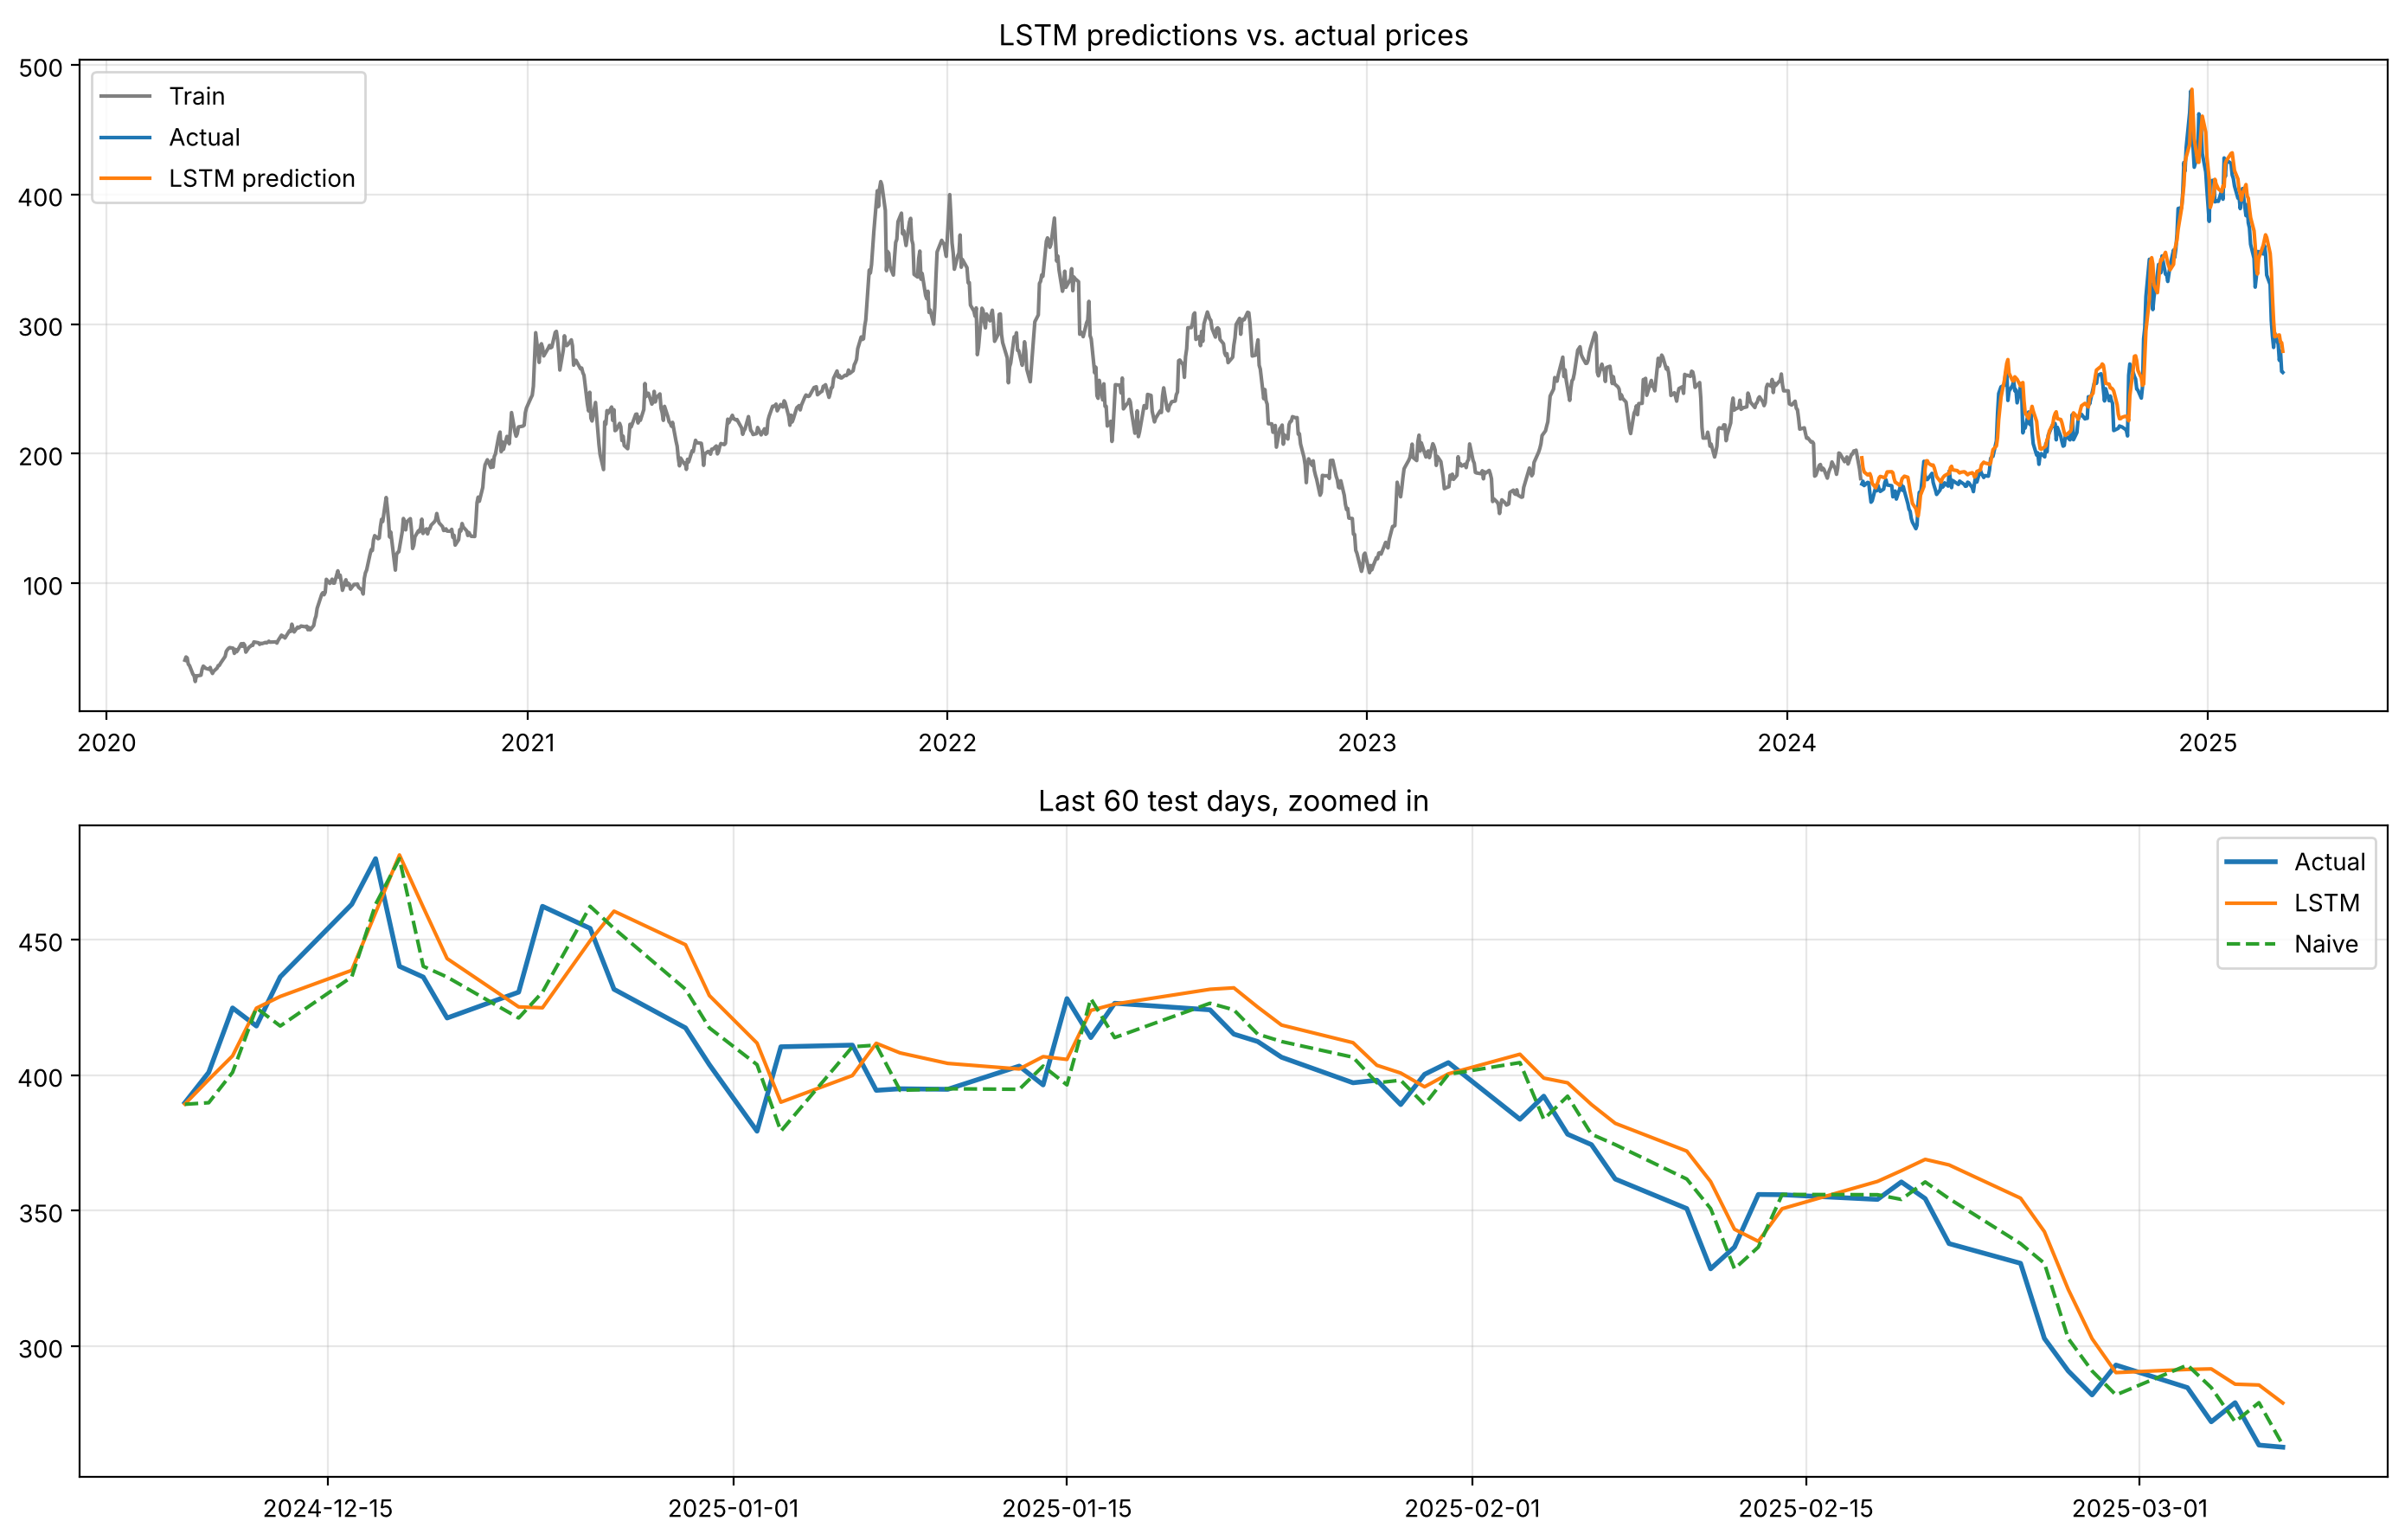

In [6]:
plot_df = pd.DataFrame({'Actual': y_test, 'LSTM': pred, 'Naive': naive}, index=prices.index[train_len:])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9))
ax1.plot(prices.index[:train_len], values[:train_len, 0], label='Train', color='gray')
ax1.plot(plot_df.index, plot_df['Actual'], label='Actual')
ax1.plot(plot_df.index, plot_df['LSTM'], label='LSTM prediction')
ax1.set_title('LSTM predictions vs. actual prices'); ax1.legend(); ax1.grid(alpha=0.3)

last = plot_df.iloc[-60:]
ax2.plot(last.index, last['Actual'], label='Actual', linewidth=2)
ax2.plot(last.index, last['LSTM'], label='LSTM')
ax2.plot(last.index, last['Naive'], label='Naive', linestyle='--')
ax2.set_title('Last 60 test days, zoomed in'); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
# 5. Conclusion

Compare the LSTM row with the naive row above. Both have a high R², because tomorrow's price is close to today's price for any model, so R² alone says little here. The real questions are whether the LSTM's RMSE and MAE are lower than the naive forecast's, and whether its directional accuracy is meaningfully above the share of up days.

On the zoomed chart, the LSTM line typically trails the actual price by about a day. That pattern means the model has largely learned to repeat recent prices rather than anticipate moves.

## Lessons
- Evaluate price forecasts against a naive baseline, not in isolation
- Fit preprocessing on training data only
- A high R² on price levels is expected and does not show predictive skill

## Next steps
- Predict daily **returns** instead of price levels, which removes the persistence effect
- Walk-forward evaluation across multiple periods
- Add features beyond past prices (volume, volatility, market index returns)